# 05 — Rótulos e históricos de vendedores

## Resumo dos resultados — 12/11/2026

Nos mesmos **24.667 pedidos de validação**, a regressão logística passou de
**619 para 672 atrasos encontrados na fila de 2.466 pedidos**.
AP: **0.1986 → 0.2168**. F1 no limiar escolhido na validação: **26.97% → 28.89%**.
O recall da fila passou de **24.82% para 26.94%**: a meta de 95% não foi atingida.

- Não foram encontrados rótulos binários divergentes das datas. A revisão alterou **quando o atraso já poderia ser conhecido**.
- Foram recuperados 331 atrasos reais de treino e 234 de validação, sem alterar os rótulos.
- Históricos trouxeram ganho agregado pequeno e variável entre meses; parte maior do ganho veio da revisão do treino.
- Foram executados oito treinos: duas coortes × dois conjuntos de atributos × dois algoritmos. O HGB ficou abaixo da regressão nos cenários testados.
- O modelo da aplicação e os arquivos originais permanecem preservados. O teste não foi avaliado nesta rodada.

## Contexto e método

Prever atraso **na aprovação** do pedido. Atraso é entrega em **dia posterior** ao prometido;
entrega no próprio dia é pontual. Os cortes continuam em 01/01/2018 e 01/05/2018.

Experimento controlado:
1. Coorte original + atributos atuais.
2. Coorte original + históricos.
3. Coorte revisada + atributos atuais.
4. Coorte revisada + históricos.

Todos são avaliados nos mesmos pedidos da validação original. A validação ampliada é apresentada separadamente.
AP e captura na fila de 10% são as comparações principais. F1, precision e recall de classificação usam
um limiar escolhido na validação comum, **diferente da regra da fila**. Não houve busca de hiperparâmetros.

### Hipóteses e limites importantes

- Coorte retrospectiva de pedidos entregues: cancelados/sem desfecho não viram negativos. O viés de seleção permanece.
- Um atraso passa a ser conhecível à meia-noite seguinte ao dia prometido, **supondo promessa estável e monitoramento de entregas sem latência**. A base não contém os snapshots necessários para comprovar essa disponibilidade operacional.
- Para os históricos, adotamos uma regra mais conservadora: desfechos entram apenas na **entrega real**. Postagens entram na data real de passagem à transportadora; volume usa aprovações anteriores.
- Eventos no mesmo instante ou depois da aprovação do pedido consultado não entram. O próprio desfecho do pedido nunca é usado como atributo.
- Históricos se atualizam durante a validação com eventos que já aconteceram, sem retreinar o classificador. Isso simula uso contínuo; não uma previsão única de todos os pedidos em 01/01.
- Em pedidos com vários vendedores, o desfecho é do pedido inteiro; não identifica qual vendedor causou o atraso. Cada par pedido-vendedor conta uma vez.
- Taxas usam suavização de força 20, definida antes do treino, com taxa global calculada somente de entregas anteriores. Ausência de histórico tem indicador próprio; durações desconhecidas permanecem ausentes até a imputação.
- Imputação, padronização e categorias são aprendidas apenas no treino. Faltam snapshots históricos de cadastro, pagamentos e promessa.
- A validação já foi consultada em vários experimentos. Os ganhos são exploratórios e exigem confirmação em dados futuros independentes; nenhuma significância estatística é alegada.

### Execução e fontes

O PostgreSQL local não respondeu em 12/11. Foi usada a cópia identificada da consulta de 11/11 em
`Modelos/experimento_ctgan/doses_20261111/snapshot_postgresql.joblib`, conferida contra os CSVs originais.
O SQL original está em `src/experimento_ctgan.py`, constante `CONSULTA`; nenhuma escrita foi feita no banco.
As associações pedido-vendedor e os eventos vêm dos CSVs reais `olist_order_items_dataset.csv` e `olist_orders_dataset.csv`.

Para repetir os treinos, a partir da raiz:
```powershell
.\.venv-ctgan\Scripts\python.exe -m src.testar_historicos_vendedores --snapshot
.\.venv-ctgan\Scripts\python.exe -m unittest tests.test_historicos_vendedores -v
```
Sem `--snapshot`, o script consulta novamente o PostgreSQL. Um protocolo diferente exige uma pasta de resultados nova.
O ambiente isolado é usado para reproduzir as versões do experimento anterior; não é usada GAN nem qualquer dado sintético aqui.
Este notebook reabre as evidências executadas, verifica seus cálculos e gera as figuras. Não retreina automaticamente.

In [1]:
from pathlib import Path
import sys
import hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, average_precision_score, f1_score
from threadpoolctl import threadpool_limits
from IPython.display import display

RAIZ = Path.cwd()
if not (RAIZ / "src").is_dir():
    RAIZ = RAIZ.parent
assert (RAIZ / "src/testar_historicos_vendedores.py").is_file()
sys.path.insert(0, str(RAIZ))
PASTA = RAIZ / "Modelos/experimento_historicos"
base = joblib.load(PASTA / "base_experimento.joblib")
pacote = joblib.load(PASTA / "comparacao.joblib")
protocolo = pacote["protocolo"]
assert hashlib.sha256((RAIZ / "src/testar_historicos_vendedores.py").read_bytes()).hexdigest() == protocolo["hash_codigo"]
for nome, digest in protocolo["hash_fontes"].items():
    arquivo = RAIZ / "Dados/pedidos_consolidados_teste.csv" if nome == "pedidos_consolidados_teste.csv" else RAIZ / "Dados/Brazilian Logistic" / nome
    assert hashlib.sha256(arquivo.read_bytes()).hexdigest() == digest
plt.rcParams.update({"figure.figsize": (11, 4.8), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Fontes e código conferidos. Versões:", protocolo["versoes"])

Fontes e código conferidos. Versões: {'pandas': '2.3.3', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}


## Dados — o que mudou nos rótulos

Os alvos continuam iguais. Antes, o rótulo só ficava disponível na entrega.
Agora, para um atraso, considera-se o dia seguinte à promessa como instante em que o descumprimento já poderia ser observado.
Para pontuais, continua sendo necessária a entrega observada. Mantém-se a regra conservadora de disponibilidade **estritamente antes** do corte.

In [2]:
auditoria = pd.read_csv(PASTA / "auditoria_rotulos.csv")
display(auditoria.style.format({"proporcao_atrasos": "{:.2%}"}))
recuperados = pd.read_csv(PASTA / "pedidos_recuperados.csv")
assert recuperados.atrasou.eq(1).all()
display(recuperados.groupby("particao").agg(pedidos_recuperados=("order_id", "size")))
assert base.order_id.is_unique
assert (base.order_delivered_customer_date.dt.normalize() > base.order_estimated_delivery_date.dt.normalize()).astype(int).eq(base.atrasou).all()
print("Nenhum alvo binário alterado; nenhum pedido duplicado.")

,coorte,particao,pedidos,atrasos,proporcao_atrasos
0,original,treino,41173,1765,4.29%
1,original,validacao,24667,2494,10.11%
2,revisada,treino,41504,2096,5.05%
3,revisada,validacao,24901,2728,10.96%


,pedidos_recuperados
particao,
treino,331
validacao,234


Nenhum alvo binário alterado; nenhum pedido duplicado.


### O que os 14 novos atributos representam

- Quantidade de desfechos conhecidos e proporção de vendedores sem histórico.
- Taxa histórica de atraso, geral e nos últimos 90 dias.
- Tempo médio já observado até postagem e até entrega.
- Quantidade de aprovações nos últimos 30 dias.
- Diferença entre prazo prometido atual e tempo de entrega histórico.

Para pedidos com vários vendedores, usamos médias, máximos ou mínimo de suporte, conforme o atributo.
Essas são associações históricas, não explicações causais. O pré-processamento passa de 159 para 182 colunas:
14 atributos mais nove indicadores de ausência.

In [3]:
from src.testar_historicos_vendedores import COLUNAS_HISTORICO
assert (base.ultimo_evento_historico.isna() | base.ultimo_evento_historico.lt(base.order_approved_at)).all()
display(base.groupby("particao").agg(
    pedidos=("order_id", "size"),
    pedidos_com_algum_vendedor_sem_historico=("hist_sem_desfecho_fracao", lambda s: int(s.gt(0).sum())),
    media_desfechos_por_vendedor=("hist_observados_media", "mean"),
).round(2))
display(base[COLUNAS_HISTORICO].head(3).T.round(3))
print("Últimos eventos estritamente anteriores à aprovação em todos os pedidos.")

,pedidos,pedidos_com_algum_vendedor_sem_historico,media_desfechos_por_vendedor
particao,,,
treino,41504,2980,96.53
validacao,24901,962,205.57


,0,1,2
hist_observados_media,0.0,0.0,0.0
hist_observados_min,0.0,0.0,0.0
hist_taxa_atraso_media,NaN,NaN,NaN
hist_taxa_atraso_max,NaN,NaN,NaN
hist_taxa_atraso_90d_media,NaN,NaN,NaN
hist_taxa_atraso_90d_max,NaN,NaN,NaN
hist_sem_desfecho_fracao,1.0,1.0,1.0
hist_postagem_dias_media,NaN,NaN,NaN
hist_postagem_dias_max,NaN,NaN,NaN
hist_entrega_dias_media,NaN,NaN,NaN


Últimos eventos estritamente anteriores à aprovação em todos os pedidos.


## Resultados — mesma validação para todas as alternativas

**24.667 pedidos, 2.494 atrasos; fila de 2.466 pedidos.** Comparação principal sem mudança do denominador.
`F1`, `precision` e `recall` usam o limiar de validação; `atrasos_top10` e `recall_top10` usam a fila fixa.

In [4]:
metricas = pd.read_csv(PASTA / "metricas_validacao.csv")
comum = metricas.loc[metricas.validacao.eq("comum")].copy()
rotulos = {("original", "atuais"): "Original", ("original", "com_historicos"): "Só históricos",
           ("revisada", "atuais"): "Só revisão", ("revisada", "com_historicos"): "Revisão + históricos"}
comum["cenario"] = [rotulos[(r.coorte_treino, r.atributos)] for r in comum.itertuples()]
display(comum[["cenario", "algoritmo", "n_treino", "n_features", "AP", "f1", "precision", "recall", "atrasos_top10", "recall_top10"]].style.format(
    {"AP": "{:.4f}", "f1": "{:.2%}", "precision": "{:.2%}", "recall": "{:.2%}", "recall_top10": "{:.2%}"}))

,cenario,algoritmo,n_treino,n_features,AP,f1,precision,recall,atrasos_top10,recall_top10
0,Original,Logistica,41173,159,0.1986,26.97%,22.27%,34.20%,619,24.82%
2,Original,HGB,41173,159,0.1497,21.51%,13.34%,55.45%,422,16.92%
4,Só históricos,Logistica,41173,182,0.2070,27.30%,22.03%,35.89%,630,25.26%
6,Só históricos,HGB,41173,182,0.1598,22.52%,15.64%,40.18%,459,18.40%
8,Só revisão,Logistica,41504,159,0.2127,28.78%,21.52%,43.42%,658,26.38%
10,Só revisão,HGB,41504,159,0.1513,21.79%,13.49%,56.70%,419,16.80%
12,Revisão + históricos,Logistica,41504,182,0.2168,28.89%,23.95%,36.41%,672,26.94%
14,Revisão + históricos,HGB,41504,182,0.1649,23.48%,15.29%,50.48%,480,19.25%


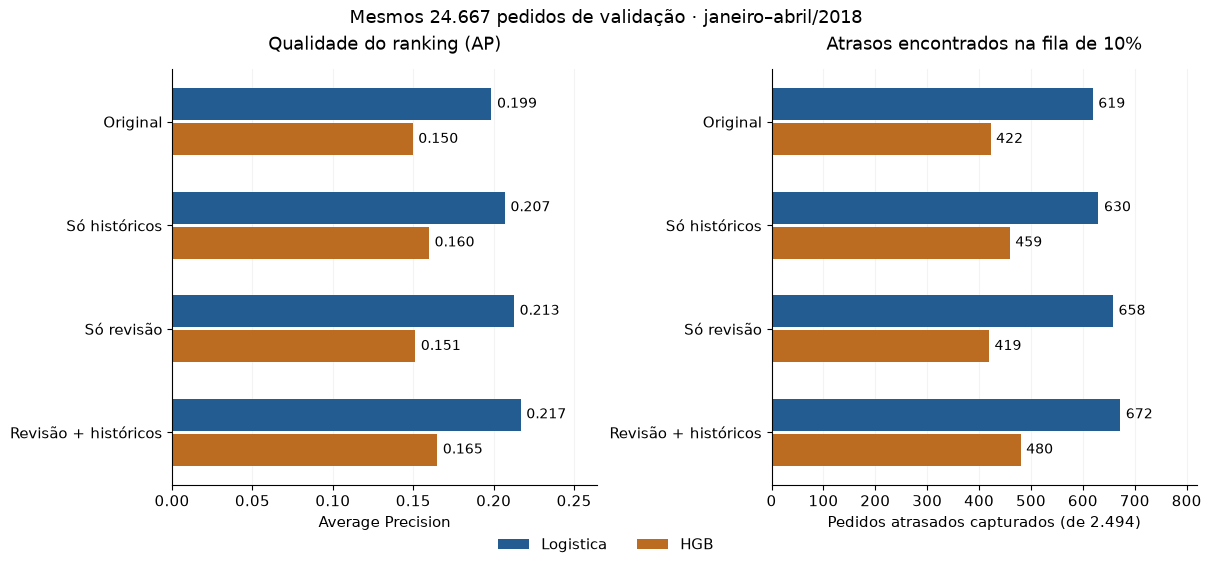

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.3), layout="constrained")
ordem = list(rotulos.values())
cores = {"Logistica": "#225c91", "HGB": "#bb6c20"}
for ax, medida, titulo, formato in zip(axes, ["AP", "atrasos_top10"],
    ["Qualidade do ranking (AP)", "Atrasos encontrados na fila de 10%"], ["{:.3f}", "{:.0f}"]):
    for j, algoritmo in enumerate(["Logistica", "HGB"]):
        tabela = comum.loc[comum.algoritmo.eq(algoritmo)].set_index("cenario").reindex(ordem)
        y = np.arange(4) + (j-.5)*.34
        barras = ax.barh(y, tabela[medida], height=.31, label=algoritmo, color=cores[algoritmo])
        ax.bar_label(barras, labels=[formato.format(x) for x in tabela[medida]], padding=4, fontsize=10)
    ax.set_yticks(range(4), ordem)
    ax.invert_yaxis()
    ax.set_xlim(0, comum[medida].max()*1.22)
    ax.set_title(titulo, pad=14)
    ax.grid(axis="x", alpha=.15)
    ax.set_axisbelow(True)
axes[0].set_xlabel("Average Precision")
axes[1].set_xlabel("Pedidos atrasados capturados (de 2.494)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(.5, -.06), ncol=2, frameon=False)
fig.suptitle("Mesmos 24.667 pedidos de validação · janeiro–abril/2018", fontsize=13)
fig.savefig(PASTA / "comparacao_historicos.png", dpi=150, bbox_inches="tight")
plt.show()

A regressão ficou acima do HGB nesta configuração. A revisão do treino trouxe a maior parcela do ganho.
Os históricos acrescentaram 11 acertos com a coorte original e 14 com a revisada.
Essa diferença não prova significância nem garante melhora em períodos futuros.

### O ganho se repete em todos os meses?

O efeito dos históricos não é uniforme: com treino revisado, AP sobe em fevereiro e cai em janeiro, março e abril.
O agregado melhora mesmo com diferenças entre os meses. As filas mensais são recalculadas em cada mês;
suas capturas não precisam somar a captura da fila global.

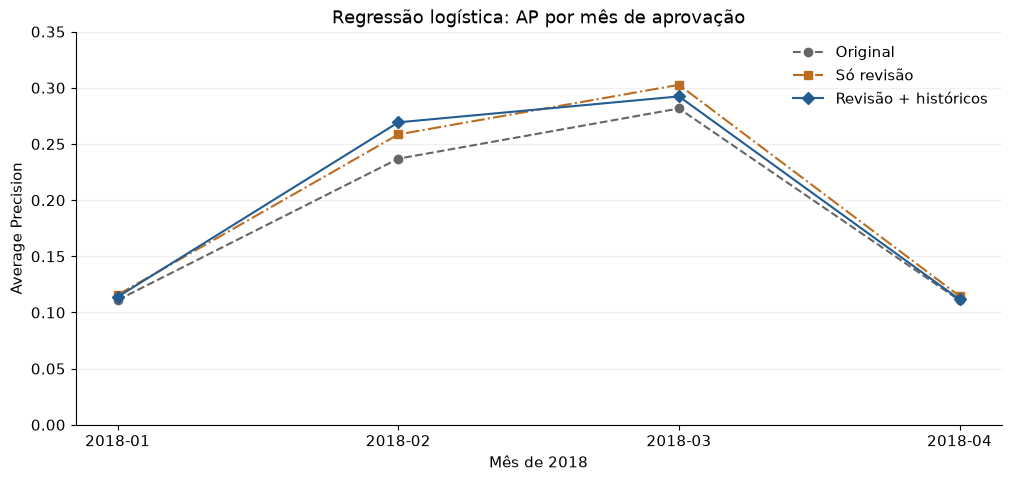

In [6]:
mensal = pd.read_csv(PASTA / "metricas_mensais.csv")
fig, ax = plt.subplots(figsize=(10, 4.7), layout="constrained")
estilos = [("original", "atuais", "#666666", "--", "o"),
           ("revisada", "atuais", "#bb6c20", "-.", "s"),
           ("revisada", "com_historicos", "#225c91", "-", "D")]
for coorte, atributos, cor, linha, marcador in estilos:
    t = mensal.loc[mensal.algoritmo.eq("Logistica") & mensal.coorte_treino.eq(coorte) & mensal.atributos.eq(atributos)].sort_values("mes")
    ax.plot(t.mes, t.AP, label=rotulos[(coorte, atributos)], color=cor, linestyle=linha, marker=marcador)
ax.set(title="Regressão logística: AP por mês de aprovação", ylabel="Average Precision", xlabel="Mês de 2018", ylim=(0, .35))
ax.grid(axis="y", alpha=.2)
ax.legend(frameon=False)
fig.savefig(PASTA / "mensal_historicos.png", dpi=150, bbox_inches="tight")
plt.show()

### Validação ampliada — comparação secundária

**24.901 pedidos, 2.728 atrasos.** Inclui 234 atrasos recuperados. Cada linha abaixo usa a mesma população ampliada.
Não comparar diretamente estes valores com os da população original para atribuir ganho ao modelo.
O limiar continua aquele escolhido na validação comum.

In [7]:
ampliada = metricas.loc[metricas.validacao.eq("ampliada") & metricas.algoritmo.eq("Logistica")]
display(ampliada[["coorte_treino", "atributos", "AP", "f1", "atrasos_top10", "precision_top10", "recall_top10"]].style.format(
    {"AP": "{:.4f}", "f1": "{:.2%}", "precision_top10": "{:.2%}", "recall_top10": "{:.2%}"}))

,coorte_treino,atributos,AP,f1,atrasos_top10,precision_top10,recall_top10
1,original,atuais,0.2205,28.85%,699,28.07%,25.62%
5,original,com_historicos,0.2296,29.37%,716,28.76%,26.25%
9,revisada,atuais,0.2370,31.04%,742,29.80%,27.20%
13,revisada,com_historicos,0.2408,31.10%,756,30.36%,27.71%


### Conferência dos modelos persistidos

Reaplica os pré-processadores e classificadores salvos aos dois conjuntos de validação.
Reconfere scores, matrizes de confusão, AP, F1 e captura da fila: 16 avaliações.

In [8]:
conferencias = []
val = base.loc[base.particao.eq("validacao") & ~base.recuperado]
ampliada_base = base.loc[base.particao.eq("validacao")]
with threadpool_limits(limits=4):
    for chave, modelo in pacote["modelos"].items():
        np.testing.assert_array_equal(val.order_id, modelo["ids_validacao"])
        for conjunto, tabela, nome_score in [("comum", val, "scores_validacao"), ("ampliada", ampliada_base, "scores_ampliada")]:
            x = modelo["preprocessador"].transform(tabela[modelo["colunas"]]).astype(np.float32)
            s = modelo["modelo"].predict_proba(x)[:, 1]
            np.testing.assert_allclose(s, modelo[nome_score], atol=1e-12, rtol=0)
            registro = metricas.loc[(metricas.coorte_treino + "_" + metricas.atributos + "_" + metricas.algoritmo).eq(chave) & metricas.validacao.eq(conjunto)].iloc[0]
            y = tabela.atrasou.to_numpy(int)
            p = s >= modelo["limiar"]
            np.testing.assert_array_equal(confusion_matrix(y, p, labels=[0, 1]).ravel(), registro[["tn", "fp", "fn", "tp"]].to_numpy(int))
            assert np.isclose(average_precision_score(y, s), registro.AP)
            assert np.isclose(f1_score(y, p), registro.f1)
            assert y[np.argsort(-s, kind="stable")[:int(.1*len(y))]].sum() == registro.atrasos_top10
            conferencias.append({"modelo": chave, "validacao": conjunto, "scores_e_metricas_reproduzidos": True})
pd.DataFrame(conferencias).to_csv(PASTA / "conferencia_metricas.csv", index=False)
print(f"Conferência aprovada: {len(conferencias)} avaliações reproduzidas.")

Conferência aprovada: 16 avaliações reproduzidas.


## Conclusões e próximo passo

Há ganho exploratório moderado. A alternativa com revisão + históricos encontra **53 atrasos adicionais** na mesma fila,
mas captura apenas **26,94% dos atrasos**. Não alcança a meta de 95%.
O F1 é 28,89% no limiar escolhido na validação; esse número **não** é o F1 da fila de 10%.

Antes de substituir o modelo da aplicação: validar em outra janela temporal, avaliar operação com filas diárias,
confirmar disponibilidade dos eventos e implementar atualização dos históricos. O modelo salvo aqui exige esses
atributos e não pode ser colocado diretamente na API atual. O teste histórico já foi visto em experimentos anteriores;
não é uma confirmação independente intocada.

### Evidências e referências

- Código: `src/testar_historicos_vendedores.py`; verificações: `tests/test_historicos_vendedores.py`.
- Dados, hashes, métricas, modelos e auditoria por pedido: `Modelos/experimento_historicos/`.
- Olist: [dataset original](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), CC BY-NC-SA 4.0.
- [Scikit-learn: prevenção de vazamento](https://scikit-learn.org/stable/common_pitfalls.html).
- [Pandas: junções temporais e correspondência estritamente anterior](https://pandas.pydata.org/docs/reference/api/pandas.merge_asof.html).
  O script usa acumulados e `searchsorted` para preservar essa semântica e calcular janelas.